ДЗ№2. Реализовать вручную класс для расчёта линейной регрессии, а также оценки качества работы по ключевым метрикам.

In [92]:
from abc import ABC, abstractmethod
from dataclasses import dataclass, field
from itertools import combinations_with_replacement
import numpy as np
from scipy.special import expit

In [93]:
def is_finite_non_negative(value):
    return np.isfinite(value) and value >= 0 if value is not None else False


def as_1d(raw_data):
    data = np.asarray(raw_data, dtype=float)
    if data.ndim > 1:
        data = data.flatten()
    return data


def as_2d(raw_data):
    data = np.asarray(raw_data, dtype=float)
    if data.ndim == 1:
        data = data.reshape(-1, 1)
    return data


def make_polynomial_features(raw_data, degree):
    data = as_2d(raw_data)

    if degree < 1:
        raise ValueError("Degree must be at least 1.")

    n_observations, n_features = data.shape
    columns = []

    for current_degree in range(1, degree + 1):
        for combination in combinations_with_replacement(
            range(n_features), current_degree
        ):
            term = np.ones(n_observations)

            for feature_index in combination:
                term *= data[:, feature_index]

            columns.append(term)

    return np.column_stack(columns)


def add_intercept(data):
    n = data.shape[0]
    intercept = np.ones((n, 1))
    return np.column_stack([intercept, data])


def sigmoid(z):
    z = np.asarray(z, dtype=float)
    return expit(z)  # numerically stable sigmoid function


def sigmoid_derivative(z):
    z = np.asarray(z, dtype=float)
    s = expit(z)
    return s * (1 - s)  # derivative of the sigmoid function


In [94]:
def mse(y_true, y_pred):
    y_true, y_pred = as_1d(y_true), as_1d(y_pred)
    return float(np.mean((y_true - y_pred) ** 2))


def mae(y_true, y_pred):
    y_true, y_pred = as_1d(y_true), as_1d(y_pred)
    return float(np.mean(np.abs(y_true - y_pred)))


def r2(y_true, y_pred):
    y_true, y_pred = as_1d(y_true), as_1d(y_pred)
    ss_total = np.sum((y_true - y_true.mean()) ** 2)
    if np.isclose(ss_total, 0):
        raise ValueError("R² is undefined when y_true is constant")
    return float(1 - np.sum((y_true - y_pred) ** 2) / ss_total)


def adjusted_r2(y_true, y_pred, n_features):
    n_samples = len(as_1d(y_true))
    if n_samples <= n_features + 1:
        raise ValueError("n_samples must be greater than n_features + 1")
    value = r2(y_true, y_pred)
    return float(1 - (1 - value) * (n_samples - 1) / (n_samples - n_features - 1))


def _binary_labels(y_true, y_pred):
    y_true, y_pred = as_1d(y_true).astype(int), as_1d(y_pred).astype(int)
    if len(y_true) != len(y_pred):
        raise ValueError("y_true and y_pred must have the same length")
    if not np.all(np.isin(y_true, [0, 1])) or not np.all(np.isin(y_pred, [0, 1])):
        raise ValueError("binary labels must be 0 or 1")
    return y_true, y_pred


def confusion_matrix(y_true, y_pred):
    y_true, y_pred = _binary_labels(y_true, y_pred)
    return np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))],
    ])


def accuracy(y_true, y_pred):
    y_true, y_pred = _binary_labels(y_true, y_pred)
    return float(np.mean(y_true == y_pred))


def precision(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return float(tp / (tp + fp)) if tp + fp else 0.0


def recall(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return float(tp / (tp + fn)) if tp + fn else 0.0


def specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return float(tn / (tn + fp)) if tn + fp else 0.0


def f1_score(y_true, y_pred):
    p, r = precision(y_true, y_pred), recall(y_true, y_pred)
    return float(2 * p * r / (p + r)) if p + r else 0.0

In [95]:
@dataclass
class Problem:
    data: np.ndarray = field(default_factory=lambda: np.array([]))
    values: np.ndarray = field(default_factory=lambda: np.array([]))

    def __post_init__(self):
        self.data = as_2d(self.data)
        self.values = as_1d(self.values)
        if self.data.shape[0] != self.values.size:
            raise ValueError("Число наблюдений в data и values должно совпадать.")

    @property
    def features(self):
        return self.data.shape[1]

    @property
    def classes(self):
        return np.unique(self.values)


@dataclass
class LinearParameters:
    coefficients: np.ndarray
    
    def __post_init__(self):
        self.coefficients = as_1d(self.coefficients)

    @property
    def features(self):
        return self.slopes.size

    @property
    def intercept(self):
        return self.coefficients[0] if self.coefficients.size else None

    @property
    def slopes(self):
        return self.coefficients[1:] if self.coefficients.size > 1 else None

    @property
    def first_slope(self):
        return self.slopes[0] if self.slopes.size else None


@dataclass
class LogisticParameters(LinearParameters):
    classes: np.ndarray

    def __post_init__(self):
        super().__post_init__()
        self.classes = as_1d(np.unique(self.classes))
        if self.classes.size != 2:
            raise ValueError("В логистической регрессии должно быть ровно два класса.")

    @property
    def num_classes(self):
        return self.classes.size


@dataclass(frozen=True, order=True)
class CVScore:
    mse: float
    degree: int
    lam: float


In [96]:
class RegressionSolver(ABC):
    def __init__(self, problem: Problem | None = None, lam: float | None = None):
        self.problem = Problem() if problem is None else problem
        self.lam = self._validate_lam(lam)
        self.params = None
        self.trained = None

    @classmethod
    def from_arrays(cls, data, values, **kwargs):
        return cls(Problem(data=data, values=values), **kwargs)

    @property
    def intercept(self):
        return self.params.intercept if self.params else None

    @property
    def slopes(self):
        return self.params.slopes if self.params else None

    @property
    def features(self):
        return self.params.features if self.params else None

    @abstractmethod
    def fit(self, data, values, **kwargs):
        """Обучить модель на данных и вычислить параметры."""
        raise NotImplementedError

    @abstractmethod
    def predict(self, data):
        """Получить предсказания для новых данных."""
        raise NotImplementedError

    @abstractmethod
    def _make_params(self, coefficients):
        """Параметры модели должны быть созданы в подклассе."""
        
    def solve(self, lam=None, **kwargs):
        """Установить параметры модели, обучив её на данных задачи."""
        if lam is not None:
            self.lam = self._validate_lam(lam)

        coefficients = self.fit(lam=self.lam, **kwargs)

        self.params = self._make_params(coefficients)
        self.trained = self.predict(self.problem.data)

        return self.params

    def _validate_params(self):
        if self.params is None:
            raise RuntimeError(
                "Model parameters are not set. Please call solve() first."
            )

    @staticmethod
    def _validate_lam(lam):
        lam = float(lam) if lam is not None else 0.0
        if not is_finite_non_negative(lam):
            raise ValueError(
                "Параметр регулязации должен быть неотрицательным конечным числом."
            )
        return lam

In [97]:
class LRSolver(RegressionSolver):
    def __init__(self, problem=None, lam=None):
        super().__init__(problem, lam)
        
    def _transform_data(self, data):
        return add_intercept(data)

    def fit(self, data=None, values=None, lam=None, **kwargs):
        data = self.problem.data if data is None else data
        values = self.problem.values if values is None else values

        values = np.asarray(values, dtype=float).reshape(-1)

        if data.shape[0] != values.size:
            raise ValueError("Число наблюдений в data и values должно совпадать.")

        lam = self.lam if lam is None else self._validate_lam(lam)
        design = self._transform_data(data)

        return self._get_coefficients(design, values, lam, **kwargs)

    def predict(self, data):
        self._validate_params()
        design = self._transform_data(data)
        return design @ self.params.coefficients
    
    def _make_params(self, coefficients):
        return LinearParameters(coefficients)

    def _get_coefficients(self, design, values, lam, **kwargs):
        return self._solve_ridge(design, values, lam)
    
    @staticmethod
    def _solve_ridge(X, Y, lam=0.0):
        """Вычисляет коэффициенты линейной регрессии с L2-регуляризацией."""
        features = X[:, 1:]  # без intercept

        feature_mean = features.mean(axis=0)
        centered_features = features - feature_mean

        feature_scale = centered_features.std(axis=0)
        threshold = 1e-12 * np.maximum(np.abs(feature_mean), 1.0)
        feature_scale = np.where(feature_scale > threshold, feature_scale, 1.0)

        design = centered_features / feature_scale

        target_mean = Y.mean()
        target = Y - target_mean

        if lam > 0:
            penalty = np.sqrt(lam) * np.eye(design.shape[1])
            design = np.vstack((design, penalty))
            target = np.concatenate((target, np.zeros(design.shape[1])))

        standardized_slopes = np.linalg.lstsq(design, target, rcond=None)[0]

        slopes = standardized_slopes / feature_scale
        intercept = target_mean - feature_mean @ slopes
        coefficients = np.concatenate(([intercept], slopes))

        return coefficients
    
    def _equation_label(self):
        intercept = self.params.intercept
        slope = self.params.first_slope  # Только для одного исходного фактора
        math_str = f"$y = {slope:.2f}x + {intercept:.2f}$"
        math_str = math_str.replace("+ -", "- ")
        return math_str

    def plot(self):
        import matplotlib.pyplot as plt

        self._validate_params()

        if self.problem.features != 1:
            raise ValueError("График доступен только для одного исходного фактора")

        x_values = self.problem.data
        y_values = self.problem.values

        x_line = np.linspace(x_values.min(), x_values.max(), 300)
        y_line = self.predict(x_line)

        plt.figure(figsize=(8, 6))

        plt.scatter(x_values, y_values, color="blue", label="Data")
        label = self._equation_label()
        plt.plot(x_line, y_line, color="green", linestyle="--", label=label)

        y_all = np.concatenate([y_values, y_line])
        margin = 0.1 * max(np.ptp(y_all), 1.0)
        plt.ylim(y_all.min() - margin, y_all.max() + margin)

        plt.xlabel("Feature")
        plt.ylabel("Value")
        plt.title("Regression get_coefficients")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()

Показательный пример работы регуляризации

In [98]:
rng = np.random.default_rng(seed=22)
n = 15
x_c = np.linspace(0, 30, n)
y_c = 3 * x_c + rng.uniform(-5, 5, len(x_c))
X_c = np.column_stack(
    [
        x_c,
        x_c + rng.normal(0, 0.01, len(x_c)),
        x_c + rng.normal(0, 0.01, len(x_c)),
    ]
)
solver_lr = LRSolver.from_arrays(X_c, y_c)

ols = solver_lr.solve(lam=0.0).slopes
ridge = solver_lr.solve(lam=0.1).slopes

print(ols, "sum:", sum(ols))
print(ridge, "sum:", sum(ridge))

[ 22.59810025  -3.888012   -15.74123074] sum: 2.968857510243156
[0.98806964 0.98797968 0.98446056] sum: 2.9605098803164243


Пример обучения модели

In [99]:
solver = LRSolver.from_arrays(x_c, y_c)
params = solver.solve()
predictions = solver.predict(x_c)
print("Intercept:", params.intercept)
print("Slopes:", params.slopes)
print("Features:", params.features)
print("R²:", r2(y_c, predictions))

Intercept: -0.02382072135310409
Slopes: [2.96739701]
Features: 1
R²: 0.9890563068790763


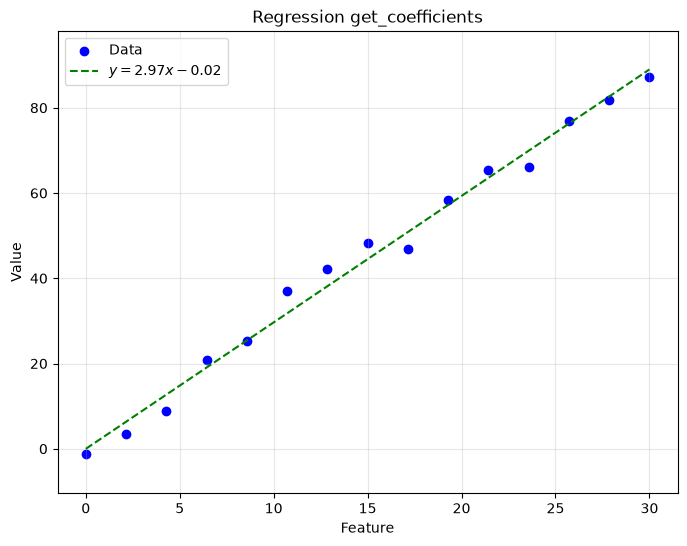

In [100]:
solver.plot()

In [101]:
class PRSolver(LRSolver):
    def __init__(self, problem=None, degree=None, lam=None):
        super().__init__(problem, lam)

        self.degree = None if degree is None else self._validate_degree(degree)
        self.best = None

    def _transform_data(self, data, degree=None):
        degree = self.degree if degree is None else self._validate_degree(degree)
        poly_features = make_polynomial_features(data, degree)
        return add_intercept(poly_features)

    def solve(self, degree=None, lam=None, **kwargs):
        best_degree = self.best.degree if self.best else None
        best_lam = self.best.lam if self.best else None

        self.degree = self._resolve_param(
            degree, best_degree, self.degree, self._validate_degree
        )
        self.lam = self._resolve_param(lam, best_lam, self.lam, self._validate_lam)

        return super().solve(lam=self.lam, **kwargs)

    @staticmethod
    def _validate_degree(degree):
        if not isinstance(degree, int) or degree < 1:
            raise ValueError("Degree must be a positive integer.")
        return degree

    @staticmethod
    def _resolve_param(explicit_value, best_value, default_value, validator):
        if explicit_value is not None:
            value = explicit_value
        elif best_value is not None:
            value = best_value
        else:
            value = default_value
        return validator(value)
    
    def cross_validate(self, degrees, lambdas=(0.0,), folds=5, random_state=42):
        data, values = self.problem.data, self.problem.values
        if folds > len(values):
            raise ValueError("folds не может быть больше числа наблюдений")
        if not degrees:
            raise ValueError("degrees не должен быть пустым")

        fold_indices = self._make_folds(len(values), folds, random_state)

        valid_degrees = [self._validate_degree(d) for d in degrees]
        valid_lambdas = [self._validate_lam(l) for l in lambdas]

        scores = []
        for degree in valid_degrees:
            for lam in valid_lambdas:
                mean_error = self._cv_mse(data, values, fold_indices, degree, lam)
                cv_score = CVScore(mean_error, degree, lam)
                scores.append(cv_score)

        self.best = min(scores)
        return self.best, tuple(scores)

    def _make_folds(self, n_samples, folds, random_state):
        rng = np.random.default_rng(random_state)
        indices = rng.permutation(n_samples)
        return np.array_split(indices, folds)

    def _cv_mse(self, data, values, folds, degree, lam):
        errors = []

        for i, valid_idx in enumerate(folds):
            train = np.concatenate(folds[:i] + folds[i + 1 :])
            errors.append(self._fold_mse(data, values, train, valid_idx, degree, lam))

        return np.mean(errors)

    def _fold_mse(self, data, values, train_idx, valid_idx, degree, lam):
        train_poly = self._transform_data(data[train_idx], degree)
        valid_poly = self._transform_data(data[valid_idx], degree)

        coefficients = self._solve_ridge(train_poly, values[train_idx], lam)
        predictions = valid_poly @ coefficients

        return mse(values[valid_idx], predictions)

    def _equation_label(self):
        terms = [f"{self.params.intercept:.2f}"]
        degree = self.degree

        for coefficient, power in zip(self.params.slopes, range(1, degree + 1)):
            sign = "+" if coefficient >= 0 else "-"
            value = abs(coefficient)

            if power == 1:
                term = f"{value:.2f}x"
            else:
                term = f"{value:.2f}x^{{{power}}}"

            terms.append(f"{sign} {term}")

        math_str = "$y = " + " ".join(terms) + "$"
        return math_str

Seed 0: CVScore(mse=np.float64(35.11409916799899), degree=3, lam=0.0)
Seed 1: CVScore(mse=np.float64(34.524474021840874), degree=3, lam=0.0)
Seed 2: CVScore(mse=np.float64(34.853779007621256), degree=3, lam=0.01)
Seed 3: CVScore(mse=np.float64(37.12639624441675), degree=3, lam=0.0)
Seed 4: CVScore(mse=np.float64(36.68899702037463), degree=3, lam=0.0)
Seed 5: CVScore(mse=np.float64(35.865295002815245), degree=3, lam=0.01)
Seed 6: CVScore(mse=np.float64(33.890368229503686), degree=3, lam=0.0)
Seed 7: CVScore(mse=np.float64(29.70532983722549), degree=4, lam=0.0)
Seed 8: CVScore(mse=np.float64(33.779886891354415), degree=3, lam=0.0)
Seed 9: CVScore(mse=np.float64(34.62083533864736), degree=3, lam=0.0)

Selected degree: 3, Selected lambda: 0.00


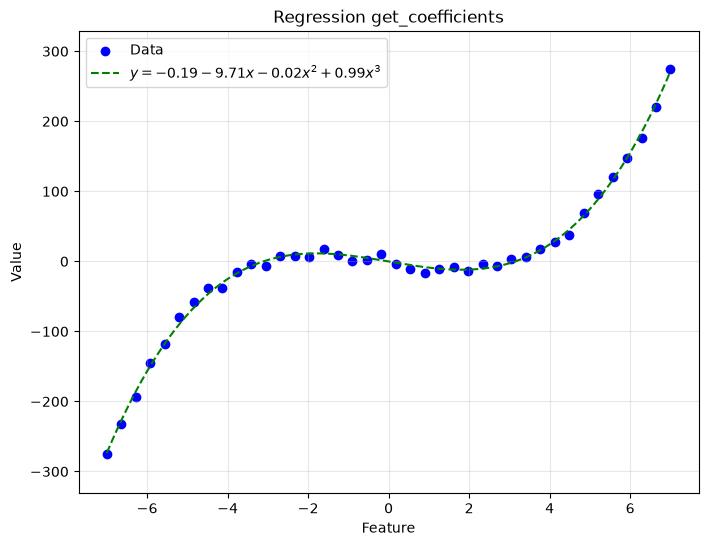

In [102]:
rng = np.random.default_rng(seed=22)

n = 40
x = np.linspace(-7, 7, n)
y = x**3 - 10 * x + rng.uniform(-10, 10, len(x))

solver_pr = PRSolver.from_arrays(x, y)
best_results = []

for seed in range(10):
    solver_pr = PRSolver.from_arrays(x, y)

    best, scores = solver_pr.cross_validate(
        degrees=range(1, 8),
        lambdas=(0.0, 0.005, 0.01, 0.1, 0.5, 0.8, 1.0, 2.0),
        folds=5,
        random_state=seed,
    )
    best_results.append(best)
    print(f"Seed {seed}: {best}")

selected_degree = int(np.mean([result.degree for result in best_results]))
selected_lam = np.mean([result.lam for result in best_results])
print(f"\nSelected degree: {selected_degree}, Selected lambda: {selected_lam:.2f}")

solver_pr.solve(degree=selected_degree, lam=selected_lam)
solver_pr.predict(x)
solver_pr.plot()


Intercept: -0.19070996101526577
Slopes: [-9.72492721 -0.01940804  0.99279705]


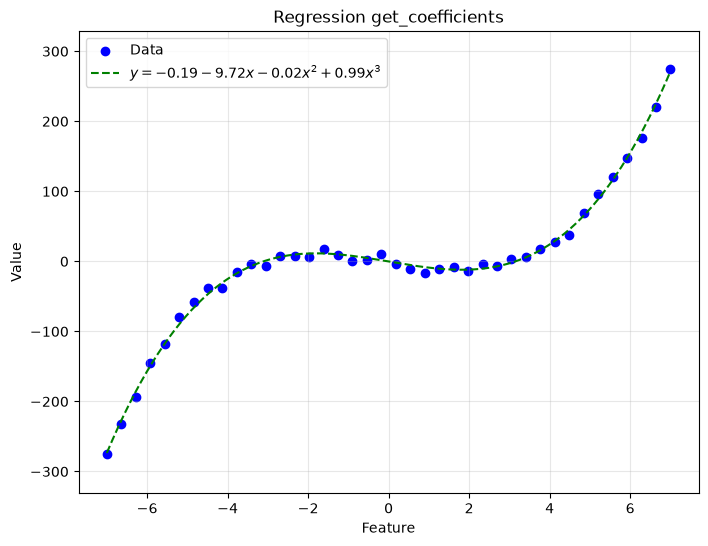

In [103]:
params = solver_pr.solve(degree=3, lam=0.0)
print("Intercept:", params.intercept)
print("Slopes:", params.slopes)
solver_pr.predict(x)
solver_pr.plot()

In [104]:
rng = np.random.default_rng(seed=22)
X = np.column_stack(
    [
        x,
        x + rng.normal(0, 0.01, len(x)),
        x + rng.normal(0, 0.01, len(x)),
    ]
)
solver_pr_reg = PRSolver.from_arrays(X, y, degree=1)
ols = solver_pr_reg.fit(lam=0.0)
ridge = solver_pr_reg.fit(lam=1.0)

print(ols[1:], "sum:", sum(ols[1:]))
print(ridge[1:], "sum:", sum(ridge[1:]))

[-1306.55455774   950.02543297   377.4783201 ] sum: 20.94919532232126
[6.78024006 7.08555993 6.90138899] sum: 20.767188984020894


In [105]:
print("Problem features:", solver_pr.problem.features)
print("Model features:", solver_pr.features)

Problem features: 1
Model features: 3


In [106]:

def armijo_condition(theta, candidate, step, epsilon, loss_fn, gradient):
    loss_current = loss_fn(theta)
    loss_candidate = loss_fn(candidate)
    lhs = loss_candidate
    rhs = loss_current - epsilon * step * np.dot(gradient, gradient)
    return lhs <= rhs

def validate_gradient_descent_parameters(shrink, epsilon):
    if not 0 < shrink < 1:
        raise ValueError("shrink должен быть в интервале (0, 1).")

    if not 0 < epsilon < 1:
        raise ValueError("epsilon должен быть в интервале (0, 1).")

def gradient_descent(
    X,
    loss_fn,
    gradient_fn,
    shrink=0.5,
    epsilon=1e-4,
    max_iter=10000,
    tolerance=1e-4,
    max_backtrack=500,
):
    validate_gradient_descent_parameters(shrink, epsilon)
    theta = np.zeros(X.shape[1])

    for _ in range(max_iter):
        gradient = gradient_fn(theta)

        if np.linalg.norm(gradient) <= tolerance:
            return theta

        step = 1.0
        accepted = False

        for _ in range(max_backtrack):
            candidate = theta - step * gradient

            if armijo_condition(
                theta, candidate, step, epsilon, loss_fn, gradient
            ):
                accepted = True
                break

            step *= shrink

        if not accepted:
            raise RuntimeError("Не удалось подобрать шаг Армихо.")

        if np.linalg.norm(candidate - theta) <= tolerance:
            return candidate

        theta = candidate

    raise RuntimeError("Gradient descent did not converge.")

In [107]:
class LogisticRegressionSolver(LRSolver):
    def __init__(self, problem=None, lam=0.0, threshold=0.5):
        super().__init__(problem, lam)

        if not 0 <= threshold <= 1:
            raise ValueError("threshold must be between 0 and 1")

        self.threshold = threshold

    def _make_params(self, coefficients):
        classes, _ = self._encode_target(self.problem.values)
        return LogisticParameters(coefficients, classes)
    
    @staticmethod
    def _encode_target(values):
        values = np.asarray(values)
        classes = np.unique(values)

        if classes.size != 2:
            raise ValueError("Logistic regression requires exactly two classes.")

        encoded_values = (values == classes[1]).astype(float)

        return classes, encoded_values

    def fit(self, data=None, values=None, lam=None, max_iter=10_000, tolerance=1e-3):
        values = self.problem.values if values is None else values
        _, encoded_values = self._encode_target(values)

        return super().fit(
            data=data,
            values=encoded_values,
            lam=lam,
            max_iter=max_iter,
            tolerance=tolerance,
        )
    
    def _get_coefficients(self, design, values, lam, max_iter=10_000, tolerance=1e-3):
        loss_fn = lambda theta: self._loss(design, values, theta, lam)
        gradient_fn = lambda theta: self._loss_gradient(design, values, theta, lam)

        return gradient_descent(
            design, loss_fn, gradient_fn, max_iter=max_iter, tolerance=tolerance
        )
    
    def predict(self, data):
        probabilities = self.predict_proba(data)
        indices = (probabilities[:, 1] >= self.threshold).astype(int)

        return self.classes[indices]

    def decision_function(self, data):
        self._validate_params()

        design = self._transform_data(data)
        return design @ self.params.coefficients

    def predict_proba(self, data):
        scores = self.decision_function(data)
        probability = sigmoid(scores)

        return np.column_stack([1.0 - probability, probability])

    @property
    def classes(self):
        return self.params.classes if self.params is not None else None

    @staticmethod
    def _loss(X, y, theta, lam=0.0):
        scores = X @ theta
        data_loss = np.mean(np.logaddexp(0.0, scores) - y * scores)
        penalty = lam / (2 * len(y)) * np.sum(theta[1:] ** 2)

        return data_loss + penalty

    @staticmethod
    def _loss_gradient(X, y, theta, lam=0.0):
        probabilities = sigmoid(X @ theta)
        gradient = X.T @ (probabilities - y) / len(y)
        # Intercept theta[0] не регуляризуется.
        gradient[1:] += lam / len(y) * theta[1:]

        return gradient

    def plot_confusion_matrix(self, labels=(0, 1), ax=None, cmap="Blues"):
        import matplotlib.pyplot as plt
        import seaborn as sns

        matrix = confusion_matrix(self.problem.values, self.trained)

        if ax is None:
            _, ax = plt.subplots(figsize=(5, 4))

        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap=cmap,
            cbar=False,
            square=True,
            xticklabels=labels,
            yticklabels=labels,
            ax=ax,
        )

        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
        ax.set_title("Confusion matrix")

        return ax

    def plot(self):
        import matplotlib.pyplot as plt

        self._validate_params()
        data = as_2d(self.problem.data)

        if data.shape[1] != 2:
            raise ValueError("plot поддерживает ровно два исходных признака.")

        x_min, x_max = data[:, 0].min(), data[:, 0].max()
        y_min, y_max = data[:, 1].min(), data[:, 1].max()

        margin_x = 0.1 * max(x_max - x_min, 1.0)
        margin_y = 0.1 * max(y_max - y_min, 1.0)

        xx, yy = np.meshgrid(
            np.linspace(x_min - margin_x, x_max + margin_x, 250),
            np.linspace(y_min - margin_y, y_max + margin_y, 250),
        )

        grid = np.column_stack([xx.ravel(), yy.ravel()])

        scores = self.decision_function(grid)
        scores = scores.reshape(xx.shape)

        plt.figure(figsize=(8, 6))

        plt.contourf(xx, yy, scores, levels=20, cmap="coolwarm", alpha=0.2)
        plt.contour(xx, yy, scores, levels=[0], colors="black", linewidths=2)

        values = self.problem.values

        for class_value in self.classes:
            mask = values == class_value
            plt.scatter(
                data[mask, 0],
                data[mask, 1],
                label=f"class {class_value:g}",
                edgecolors="black",
            )

        plt.xlabel("Feature 1")
        plt.ylabel("Feature 2")
        plt.title("Logistic regression decision boundary")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()

Classes: [0. 1.]
Intercept: 0.14719658306815514
Slopes: [0.31828713 0.72927636]
Accuracy: 0.835


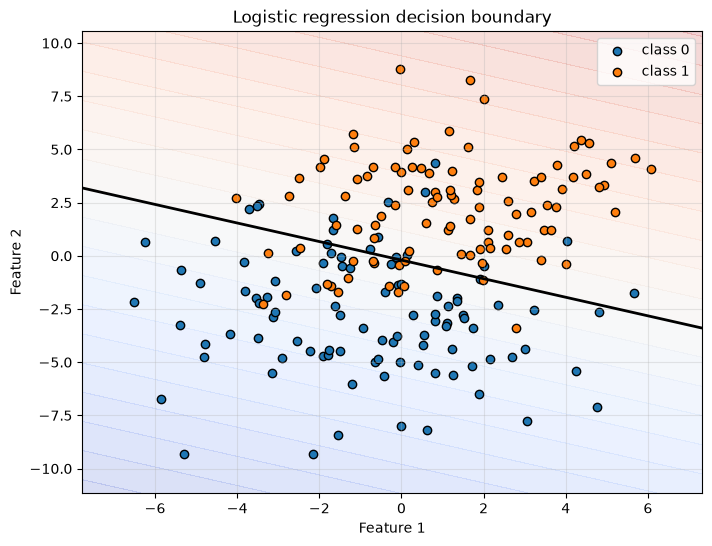

In [108]:
rng = np.random.default_rng(2)

n = 100

class_0 = rng.normal(
    loc=[-1.0, -2.5],
    scale=2.8,
    size=(n, 2),
)

class_1 = rng.normal(
    loc=[1.0, 2.5],
    scale=2.2,
    size=(n, 2),
)

X_logistic = np.vstack([class_0, class_1])
y_logistic = np.r_[
    np.zeros(n),
    np.ones(n),
]

logistic_solver = LogisticRegressionSolver.from_arrays(
    X_logistic,
    y_logistic,
    lam=0.0,
)

params = logistic_solver.solve()

print("Classes:", params.classes)
print("Intercept:", params.intercept)
print("Slopes:", params.slopes)
print(
    "Accuracy:",
    np.mean(logistic_solver.predict(X_logistic) == y_logistic),
)

logistic_solver.plot()

In [112]:
y_pred = logistic_solver.predict(X_logistic)
y_proba = logistic_solver.predict_proba(X_logistic)[:, 1]

print("Accuracy:", accuracy(y_logistic, y_pred))
print("Precision:", precision(y_logistic, y_pred))
print("Recall:", recall(y_logistic, y_pred))
print("F1:", f1_score(y_logistic, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_logistic, y_pred))

Accuracy: 0.835
Precision: 0.845360824742268
Recall: 0.82
F1: 0.83248730964467
Confusion Matrix:
 [[85 15]
 [18 82]]


<Axes: title={'center': 'Confusion matrix'}, xlabel='Predicted label', ylabel='True label'>

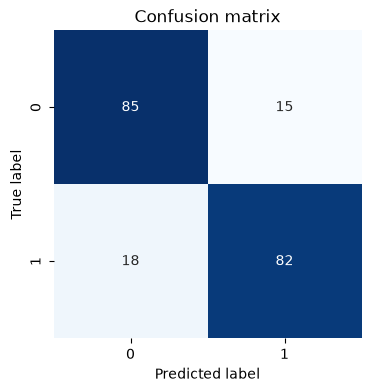

In [113]:
logistic_solver.plot_confusion_matrix()
